# Paper 19: FCF layers

v2 keeps the **top half of Halal S&P 500 names by FCF / sales**. That is a rank cutoff, not a quality hurdle. This paper stacks three later filters on that same margin cut, one at a time:

1. **Conversion** — keep names with FCF / EBITDA ≥ 0.50 (cash actually shows up after operating profit).
2. **Stability** — keep names whose FCF was positive on at least 75% of the last 36 month-end snapshots.
3. **Yield** — drop the cheapest 20% of the remaining list by FCF / enterprise value.

A layer whose parameter is `None` is off. A layer that would leave fewer than 20 names on a date is skipped that date. Do **not** replace the median cut with a hard FCF-margin floor — that is paper 24.

Change only `signal`. Overlay, construction, execution, and screens stay on v2. Scored against **v2 baseline**. Kill rules are frozen in `Research/book-construction-status.md`:

- Train 2022 calendar more than 5pp worse than SPUS
- Train max drawdown worse than SPUS
- Train Calmar below both v2 baseline and SPUS
- Test 2023 calendar more than 15pp worse than v2 baseline

**Variants.** conversion, stability, yield-drop, all-layers.


In [1]:
import subprocess
import sys
from pathlib import Path

def _repo_root() -> Path:
    start = Path.cwd().resolve()
    for candidate in (start, *start.parents):
        if (candidate / "monterey" / "__init__.py").exists():
            return candidate
    raise FileNotFoundError(f"Monterey repo root not found from {start}")

_ROOT = _repo_root()
if str(_ROOT) not in sys.path:
    sys.path.insert(0, str(_ROOT))
try:
    import monterey  # noqa: F401
except ModuleNotFoundError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-e", f"{_ROOT}[research]"])

from monterey.research import boot, compare, run_book
from monterey.sprints import score_against_baseline
from monterey.spec import BookSpec

rd = boot("paper-19-fcf-layers", start="2019-12-01", end="2026-09-30")
print("snapshot", rd.manifest.get("hash"))
print("v2 hash", BookSpec.load("fcf-sma-v2-baseline").hash())

base = run_book(
    "fcf-sma-v2-baseline",
    rd,
    paper="19-fcf-layers",
    id="v2",
)


[monterey.data] Loading snapshot ebbbefb35545
        field                   value
       window 2019-12-01 → 2026-09-30
     universe    sp500, point-in-time
      symbols                     631
    snapshots                      85
   price rows                 1147266
    dividends                    9754
filing events                   61274
   halalquant                   0.4.0
snapshot hash            ebbbefb35545
snapshot ebbbefb35545
v2 hash 6ca86844209e


## One layer at a time

Each trial copies v2 and changes only `signal.brain` / `signal.params`. `keep_quantile=0.5` and `min_holdings=20` stay. The last trial stacks all three layers so we can see whether the combination is just the union of the singles.


In [2]:
conversion = run_book(
    "fcf-sma-v2-baseline",
    rd,
    paper="19-fcf-layers",
    id="conversion",
    signal={"brain": "fcf_layers", "params": {"conversion_min": 0.5, "min_holdings": 20}},
)
stability = run_book(
    "fcf-sma-v2-baseline",
    rd,
    paper="19-fcf-layers",
    id="stability",
    signal={"brain": "fcf_layers", "params": {"stability_min_positive": 0.75, "min_holdings": 20}},
)
yield_drop = run_book(
    "fcf-sma-v2-baseline",
    rd,
    paper="19-fcf-layers",
    id="yield-drop",
    signal={"brain": "fcf_layers", "params": {"yield_drop_quantile": 0.2, "min_holdings": 20}},
)
all_layers = run_book(
    "fcf-sma-v2-baseline",
    rd,
    paper="19-fcf-layers",
    id="all-layers",
    signal={
        "brain": "fcf_layers",
        "params": {
            "conversion_min": 0.5,
            "stability_min_positive": 0.75,
            "yield_drop_quantile": 0.2,
            "min_holdings": 20,
        },
    },
)

trials = [conversion, stability, yield_drop, all_layers]
for book in [base, *trials]:
    print(book.spec.id, book.spec.hash())
    print(" ", dict(book.spec.summary()))


v2 6ca86844209e
  {'book': 'v2', 'hash': '6ca86844209e', 'universe': 'sp500 point-in-time', 'sector screen': 'on', 'AAOIFI lines': 'debt 30% / cash 30% / recv 70%', 'breach exit': 'next_open', 'brain': 'fcf_quality (keep_quantile=0.5, min_holdings=20)', 'weights': 'cap', 'name cap': '10%', 'sector cap': 'none', 'throttle': 'SPY 200-day SMA', 'rebalance': 'daily_to_target, drift band 0.0%, min $100', 'dividends': 'credited', 'cost': '10 bp charged', 'purify': 'ex_date'}
conversion 23b12dbee832
  {'book': 'conversion', 'hash': '23b12dbee832', 'universe': 'sp500 point-in-time', 'sector screen': 'on', 'AAOIFI lines': 'debt 30% / cash 30% / recv 70%', 'breach exit': 'next_open', 'brain': 'fcf_layers (conversion_min=0.5, keep_quantile=0.5, min_holdings=20)', 'weights': 'cap', 'name cap': '10%', 'sector cap': 'none', 'throttle': 'SPY 200-day SMA', 'rebalance': 'daily_to_target, drift band 0.0%, min $100', 'dividends': 'credited', 'cost': '10 bp charged', 'purify': 'ex_date'}
stability 27b7d7f

In [3]:
compare([base, *trials], rd)


,total_return,cagr,volatility,max_drawdown,calmar,sharpe,sortino,turnover,costs_pct,dividends_pct,avg_exposure,switches,hash
book,,,,,,,,,,,,,
v2,1.0644,0.1137,0.1463,-0.2482,0.4582,0.6752,0.8589,4.1653,0.0561,0.0561,0.8032,36.0000,6ca86844209e
conversion,0.5898,0.0713,0.1294,-0.2570,0.2775,0.4442,0.5760,5.7806,0.0778,0.0722,0.8032,36.0000,23b12dbee832
stability,0.9396,0.1035,0.1413,-0.2452,0.4219,0.6282,0.8024,4.1547,0.0559,0.0597,0.8032,36.0000,27b7d7fceef2
yield-drop,1.0924,0.1160,0.1327,-0.2414,0.4803,0.7452,0.9375,4.9356,0.0664,0.0701,0.8032,36.0000,3b16eafe1264
all-layers,0.7638,0.0880,0.1257,-0.2351,0.3742,0.5769,0.7490,5.7397,0.0773,0.0804,0.8032,36.0000,21a27624bc19
SPUS (total return),2.1167,0.1840,0.2116,-0.3080,0.5975,0.8123,1.0828,NaN,NaN,NaN,NaN,NaN,NaN
SPY (total return),1.6113,0.1533,0.2006,-0.3372,0.4547,0.7140,0.8854,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:
for trial in trials:
    verdict = score_against_baseline(trial, base, rd)
    reasons = "; ".join(verdict["reasons"]) or "pass"
    print(trial.spec.id, "KILLED" if verdict["killed"] else "keep", reasons)


conversion KILLED train Calmar below both v2 baseline and SPUS
stability KILLED train Calmar below both v2 baseline and SPUS
yield-drop keep pass
all-layers KILLED train Calmar below both v2 baseline and SPUS


## Did the layer bind?

`compare` only sees NAV. Before we trust a Calmar move, check that conversion / stability / yield actually cut names on real month-ends. If a layer is skipped because it would leave fewer than 20 names, the trial is still the median FCF book that day.


In [5]:
import pandas as pd
from monterey.layers import screen
from monterey.layers.signals import Context, run_brain
from monterey.spec import BookSpec

DAYS = ["2020-03-31", "2022-06-30", "2023-12-29", "2024-12-31"]

SPECS = {
    "v2": BookSpec.load("fcf-sma-v2-baseline"),
    "conversion": BookSpec.load("fcf-sma-v2-baseline").replace(
        id="conversion",
        signal={"brain": "fcf_layers", "params": {"conversion_min": 0.5, "min_holdings": 20}},
    ),
    "stability": BookSpec.load("fcf-sma-v2-baseline").replace(
        id="stability",
        signal={"brain": "fcf_layers", "params": {"stability_min_positive": 0.75, "min_holdings": 20}},
    ),
    "yield-drop": BookSpec.load("fcf-sma-v2-baseline").replace(
        id="yield-drop",
        signal={"brain": "fcf_layers", "params": {"yield_drop_quantile": 0.2, "min_holdings": 20}},
    ),
    "all-layers": BookSpec.load("fcf-sma-v2-baseline").replace(
        id="all-layers",
        signal={
            "brain": "fcf_layers",
            "params": {
                "conversion_min": 0.5,
                "stability_min_positive": 0.75,
                "yield_drop_quantile": 0.2,
                "min_holdings": 20,
            },
        },
    ),
}


def pick(spec, day: str) -> pd.DataFrame:
    held = screen(rd, day, spec)
    return run_brain(Context(data=rd, spec=spec, as_of=pd.Timestamp(day).date(), screen=held))


rows = []
for day in DAYS:
    base_names = set(pick(SPECS["v2"], day)["symbol"].astype(str))
    for name, spec in SPECS.items():
        picked = pick(spec, day)
        names = set(picked["symbol"].astype(str)) if not picked.empty else set()
        layers = ""
        if not picked.empty and "layers" in picked.columns:
            layers = str(picked["layers"].iloc[0])
        rows.append(
            {
                "day": day,
                "book": name,
                "n": len(names),
                "dropped_vs_v2": len(base_names - names),
                "added_vs_v2": len(names - base_names),
                "median_fcf_margin": float(picked["score"].median()) if not picked.empty else None,
                "layers": layers,
            }
        )

census = pd.DataFrame(rows)
census


,day,book,n,dropped_vs_v2,added_vs_v2,median_fcf_margin,layers
0,2020-03-31,v2,83,0,0,0.0677,
1,2020-03-31,conversion,83,0,0,0.0677,margin
2,2020-03-31,stability,83,0,0,0.0677,margin+stability
3,2020-03-31,yield-drop,66,17,0,0.0766,margin+yield
4,2020-03-31,all-layers,66,17,0,0.0766,margin+stability+yield
5,2022-06-30,v2,99,0,0,0.1110,
6,2022-06-30,conversion,61,38,0,0.1304,margin+conversion
7,2022-06-30,stability,92,7,0,0.1111,margin+stability
8,2022-06-30,yield-drop,79,20,0,0.1163,margin+yield
9,2022-06-30,all-layers,45,54,0,0.1447,margin+conversion+stability+yield


In [6]:
day = "2024-12-31"
v2_pick = pick(SPECS["v2"], day).set_index("symbol")
stacked = pick(SPECS["all-layers"], day).set_index("symbol")

print("v2 names", len(v2_pick), "all-layers names", len(stacked))
print("layers column", stacked["layers"].iloc[0] if not stacked.empty and "layers" in stacked.columns else "(none)")

dropped = v2_pick.index.difference(stacked.index)
kept_out = stacked.reindex(dropped)  # empty; show v2 scores of dropped names
print("dropped from v2 on", day, len(dropped))
cols = [c for c in ("score", "market_cap") if c in v2_pick.columns]
display(v2_pick.loc[dropped, cols].sort_values("score", ascending=False).head(15))

print("kept extras vs v2", stacked.index.difference(v2_pick.index).tolist())


v2 names 100 all-layers names 21
layers column margin+conversion+stability+yield
dropped from v2 on 2024-12-31 79


,score,market_cap
symbol,,
MSFT,0.3022,"3,133,431,000,000.0000"
INTU,0.2882,"176,148,438,000.0000"
JKHY,0.2302,"12,801,282,722.8546"
WDAY,0.1922,"69,293,698,142.1814"
SWKS,0.1782,"14,179,932,048.7976"
VRSN,0.1648,"19,950,944,647.2168"
PH,0.1497,"82,836,383,739.7273"
CME,0.1469,"83,600,243,931.9611"
FAST,0.1408,"20,597,943,120.8217"


kept extras vs v2 []


## Path, not just the scorecard

Kill rules decide keep vs killed. They do not show how the books made or lost money. Plot **NAV** (growth of $1) and **drawdown**. Then plot **name count** — that is the quantity this brain claims to change.


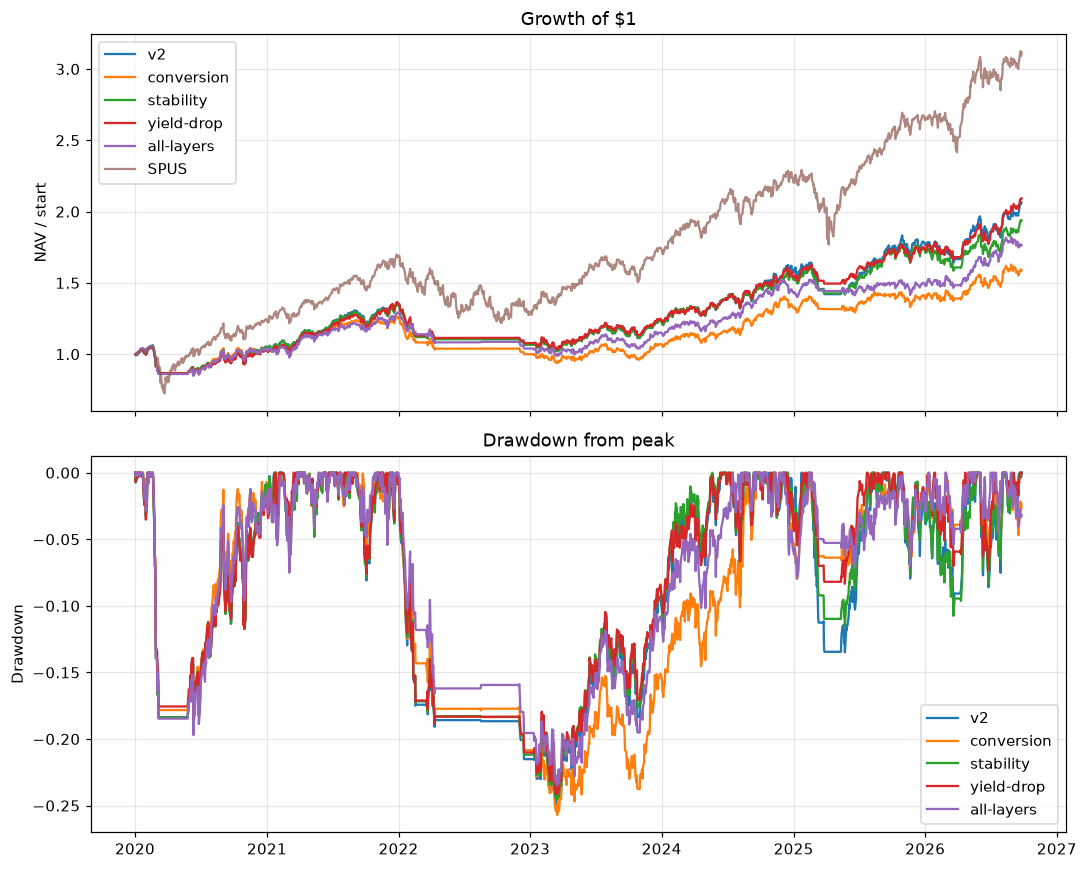

wrote figures/nav-and-drawdown.png


In [7]:
import matplotlib.pyplot as plt
from monterey.diagnostics import yearly

books = [base, *trials]
figures = Path("figures")
figures.mkdir(exist_ok=True)

spus = rd.total_return("SPUS").reindex(base.nav_series().index).ffill()

fig, axes = plt.subplots(2, 1, figsize=(10, 8), sharex=True)
for book in books:
    nav = book.nav_series()
    growth = nav / nav.iloc[0]
    axes[0].plot(growth.index, growth, label=book.spec.id)
    dd = nav / nav.cummax() - 1.0
    axes[1].plot(dd.index, dd, label=book.spec.id)

axes[0].plot(spus.index, spus / spus.iloc[0], label="SPUS", alpha=0.7)
axes[0].set_title("Growth of $1")
axes[0].set_ylabel("NAV / start")
axes[0].legend()
axes[1].set_title("Drawdown from peak")
axes[1].set_ylabel("Drawdown")
axes[1].legend()

fig.tight_layout()
fig.savefig(figures / "nav-and-drawdown.png", dpi=140)
plt.show()
print("wrote", figures / "nav-and-drawdown.png")


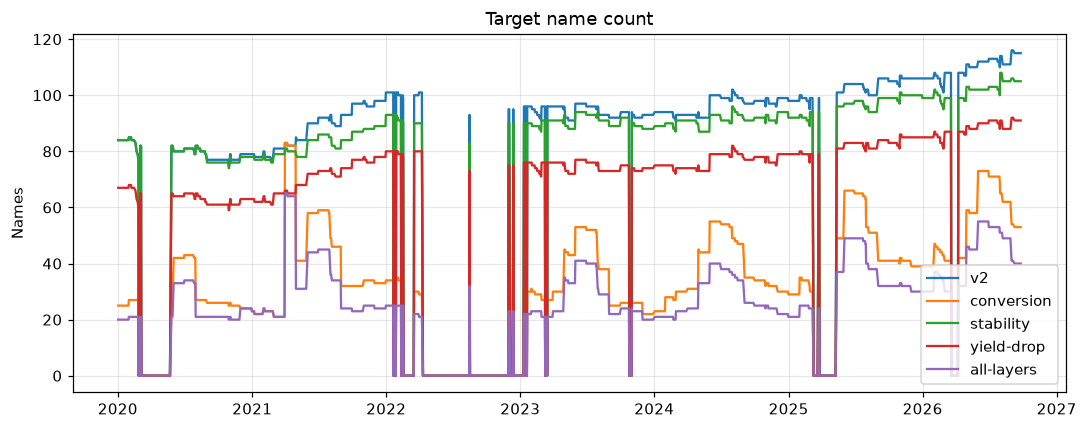

wrote figures/name-count.png


In [8]:
fig, ax = plt.subplots(figsize=(10, 4))
for book in books:
    ax.plot(book.nav["date"], book.nav["n_targets"], label=book.spec.id)
ax.set_title("Target name count")
ax.set_ylabel("Names")
ax.legend()
fig.tight_layout()
fig.savefig(figures / "name-count.png", dpi=140)
plt.show()
print("wrote", figures / "name-count.png")


,v2,conversion,stability,yield-drop,all-layers,SPUS
year,,,,,,
2020,0.0528,0.0487,0.0523,0.0302,0.0402,0.2399
2021,0.2831,0.2039,0.2743,0.3142,0.2418,0.3562
2022,-0.2080,-0.2084,-0.2051,-0.2043,-0.1953,-0.2276
2023,0.1525,0.0721,0.1572,0.1557,0.1085,0.3420
2024,0.2741,0.2365,0.2354,0.2364,0.2422,0.2649
2025,0.1250,0.0533,0.1301,0.1238,0.0360,0.1978
2026,0.1681,0.1392,0.1264,0.2097,0.1896,0.1802


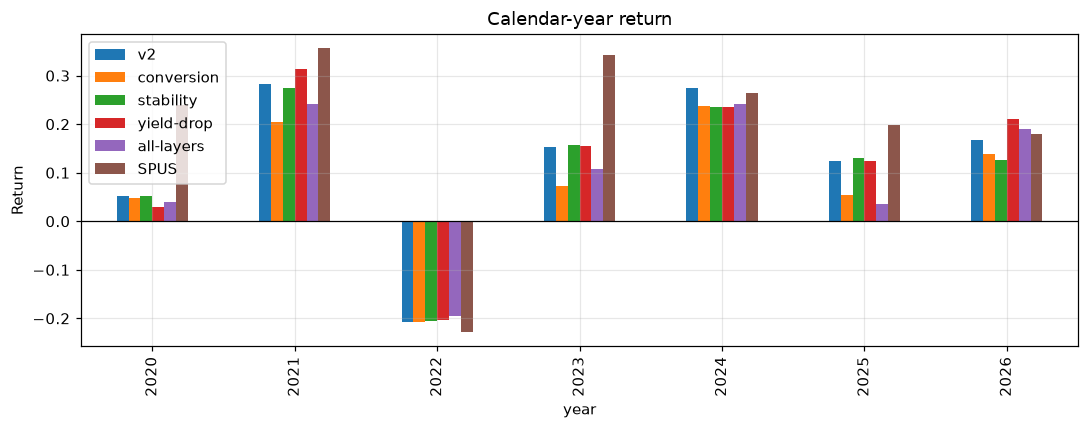

wrote figures/calendar-returns.png


In [9]:
calendar = pd.concat(
    {book.spec.id: yearly(book.nav_series())["return"] for book in books},
    axis=1,
)
calendar["SPUS"] = yearly(spus)["return"]
display(calendar)

ax = calendar.plot(kind="bar", figsize=(10, 4))
ax.set_title("Calendar-year return")
ax.set_ylabel("Return")
ax.axhline(0, color="black", lw=0.8)
fig = ax.get_figure()
fig.tight_layout()
fig.savefig(figures / "calendar-returns.png", dpi=140)
plt.show()
print("wrote", figures / "calendar-returns.png")


## Construction side effects

A tighter brain can still be the same mega-cap tech book with a shorter tail. Read positions for mean FCF score, IT weight, and top-five weight. `compare` cannot see those.


In [10]:
from monterey.diagnostics import diagnose


def live_book(ledger) -> pd.DataFrame:
    pos = ledger.positions.copy()
    pos["date"] = pd.to_datetime(pos["date"])
    pos["invested_weight"] = pos["invested_weight"].astype(float)
    pos["score"] = pd.to_numeric(pos.get("score"), errors="coerce")
    return pos[pos["invested_weight"] > 0]


def it_share(live: pd.DataFrame) -> float:
    if live.empty:
        return float("nan")
    tot = live.groupby("date")["invested_weight"].sum()
    it = live[live["sector"].fillna("").str.lower().str.contains("information technology")]
    daily = it.groupby("date")["invested_weight"].sum().reindex(tot.index).fillna(0.0) / tot
    return float(daily.mean())


def top5_share(live: pd.DataFrame) -> float:
    if live.empty:
        return float("nan")
    daily = (
        live.sort_values(["date", "invested_weight"], ascending=[True, False])
        .groupby("date")["invested_weight"]
        .apply(lambda s: float(s.head(5).sum()))
    )
    tot = live.groupby("date")["invested_weight"].sum()
    return float((daily / tot).mean())


side = []
for book in books:
    live = live_book(book)
    last = live[live["date"] == live["date"].max()] if not live.empty else live
    diag = diagnose(book, rd, write=True)
    side.append(
        {
            "book": book.spec.id,
            "mean_targets": float(book.nav["n_targets"].mean()),
            "mean_score": float(live["score"].mean()) if not live.empty else None,
            "mean_it": it_share(live),
            "mean_top5": top5_share(live),
            "last_it": float(
                last.loc[
                    last["sector"].fillna("").str.lower().str.contains("information technology"),
                    "invested_weight",
                ].sum()
            ) if not last.empty else None,
            "last_n": int(last["symbol"].nunique()) if not last.empty else 0,
            "turnover": diag.get("trading", {}).get("turnover"),
        }
    )

pd.DataFrame(side).set_index("book")


,mean_targets,mean_score,mean_it,mean_top5,last_it,last_n,turnover
book,,,,,,,
v2,76.2979,0.1312,0.4376,0.4193,0.6557,115,None
conversion,31.6401,0.1813,0.3205,0.4484,0.4440,53,None
stability,72.2589,0.1182,0.4217,0.4180,0.6458,105,None
yield-drop,60.7665,0.1412,0.4094,0.4049,0.5698,91,None
all-layers,24.4888,0.1539,0.3265,0.4768,0.4195,40,None


## Conclusion

**Would we run this?** Not as a stack. The live brain stays the v2 median FCF-margin cut. Conversion, stability, and all three layers together fail the frozen kill rules. Only the 20% FCF/EV tail drop passes, and the gain is small.

**What we asked.** v2 keeps the top half of Halal S&P 500 names by FCF / sales. That is a rank, not a quality line. This paper stacked three later filters on that same cut, one at a time, with the rest of the book unchanged: conversion (FCF / EBITDA ≥ 0.50), stability (positive FCF on at least 75% of the last 36 month-end snapshots), and yield (drop the cheapest 20% by FCF / enterprise value). Score is Calmar and max drawdown versus v2, not beating SPUS.

**What happened.**

- The filters are real. On 31 December 2024, v2 held 100 names. Conversion cut that to 29. Yield-drop cut it to 80. All three together left 21. Conversion dropped Microsoft and Nvidia even though their FCF margins were high. That is not a data bug; it is the conversion rule.
- Conversion and the full stack hurt the path. CAGR fell from 11.4% to 7.1% and 8.8%. Train Calmar fell below both v2 and SPUS, so both are killed. 2023 is the damage: v2 +15.3%, conversion +7.2%.
- Stability barely changes the list (a handful of names) and still fails on train Calmar.
- Yield-drop is the only keep: total return +109% versus v2 +106%, max drawdown −24.1% versus −24.8%, Calmar 0.48 versus 0.46. It is still the same mega-cap book with a shorter tail. Last-session IT stays high. SPUS Calmar is still 0.60.

**What this means for the fund.** Making the FCF list “stricter” on top of the median cut does not fix the invested-day lag versus SPUS. The lag is not a missing conversion or stability layer. It is the cash switch, the mega-caps, and the tech weight — papers 16, 20, and 21–25. Paper 24 can still test a hard FCF-margin floor (a yes/no line, not a ranked stack). That is a different question.

**Live rule.** Keep `fcf_quality` with `keep_quantile=0.5`. Do not promote `fcf_layers`. The 20% yield trim is optional research, not a mandate upgrade. Quote investors on the v2 brain until a later paper beats it on Calmar without failing 2022 or 2023.
